In [1]:
# =====================================================================================================
# Toxoplasma gondii seropositivity — DEEP LEARNING track (regularization + knowledge distillation)
# Same data / split / folds / metric as the ML paper, so every number is directly comparable:
#   NHANES 2013-2014 adults (n = 5,006), stratified 80/20 split (seed 42; test = 1,002, 150 positive),
#   RepeatedStratifiedKFold 5x3 on the training set, ROC-AUC, Nadeau-Bengio corrected t-test, bootstrap CI.
# Workflow:
#   STEP 1  sanity checks (initial loss, overfit a tiny batch, learning-rate range test)
#   STEP 2  bias / variance diagnosis of a big unregularized network
#   STEP 3  regularization ablation (L2, dropout, input dropout, batch norm, noise, label smoothing, mixup, max-norm,
#           weight decay, smaller network, early stopping, combinations)
#   STEP 4  random hyperparameter search (5-fold CV)          STEP 5  learning curve
#   STEP 6  error analysis                                     STEP 7  teachers (LR, RF, XGBoost, deep ensemble)
#   STEP 8  KD                STEP 9  MTKD                     STEP 10 deep mutual learning
#   STEP 11 self-distillation (born-again networks, BYOT)      STEP 12 on-policy distillation
#   STEP 13 final 5x3 CV comparison of all methods             STEP 14 one-shot evaluation on the held-out test set
# Run from the repo root or from deeplearning/.  Set FAST = True for a quick smoke run (~25 min CPU).
# Full run: roughly 4-6 h on a laptop CPU (STEP 13 is most of it, and it resumes if interrupted); far less on a GPU.
# To halve STEP 13-14, set final_feature_sets=['markers'].
# =====================================================================================================
# !pip install torch xgboost scikit-learn pandas matplotlib scipy
import os, sys, json, time, copy, math, random, warnings
warnings.filterwarnings('ignore'); os.environ['PYTHONWARNINGS'] = 'ignore'
if os.path.basename(os.getcwd()) in ('deeplearning', 'research_r'):
    os.chdir('..')
sys.path.insert(0, 'scripts')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, log_loss, brier_score_loss
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
import build_bio_features as bbf
warnings.filterwarnings('ignore')

FAST = False
CFG = dict(seed=42, feature_set='markers', final_feature_sets=['baseline', 'markers'],
           n_splits=5, n_repeats=1 if FAST else 3, es_frac=0.15,
           max_epochs=40 if FAST else 300, patience=8 if FAST else 30,
           ablation_epochs=30 if FAST else 200, ablation_seeds=1 if FAST else 3,
           n_trials=3 if FAST else 40, grid_seeds=1 if FAST else 3,
           teacher_inner_folds=3, teacher_members=2 if FAST else 3, ens_members=2 if FAST else 5,
           n_boot=200 if FAST else 1000)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(max(1, os.cpu_count() or 1))
OUT = os.path.join('deeplearning', 'results'); os.makedirs(OUT, exist_ok=True)
PAPER = {'LR baseline CV': 0.722, 'LR baseline test': 0.712, 'best ML CV (improved)': 0.740, 'best ML test (improved)': 0.730}


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'legend.frameon': False, 'font.size': 9})
BLUE, ORANGE, GREEN, GREY, PURPLE, RED = '#1f5fa8', '#d9622b', '#3f8f5a', '#9a9a9a', '#7a4f9a', '#b8312f'
print('device:', DEV, '| torch', torch.__version__, '| FAST =', FAST)

device: cpu | torch 2.10.0 | FAST = False


In [2]:
# ---------------------------------------------------------------- data, split, folds, preprocessing (identical to the paper)
TARGET = 'target_toxo_pos'
df = pd.read_csv(bbf.OUT_CSV)
CAT = ['RIAGENDR', 'RIDRETH3', 'yrs_in_us_grp', 'SLQ050', 'smoking_status', 'toxocara_pos']
DEMO = ['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'yrs_in_us_grp', 'DMDEDUC2', 'INDFMPIR']
BEH = ['HSD010', 'SLD010H', 'SLQ050', 'smoking_status', 'drinks_per_day', 'phq9_total_score']
SETS = {'baseline': DEMO + ['toxocara_pos'],
        'lifestyle': DEMO + ['toxocara_pos'] + BEH,
        'markers': DEMO + ['toxocara_pos'] + BEH + bbf.NEW_FEATURES}

X_all, y_all = df.drop(columns=[TARGET]), df[TARGET].astype(int)
Xtr_df, Xte_df, ytr, yte = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=CFG['seed'])
Xtr_df, Xte_df = Xtr_df.reset_index(drop=True), Xte_df.reset_index(drop=True)
ytr, yte = ytr.to_numpy(), yte.to_numpy()
CV = list(RepeatedStratifiedKFold(n_splits=CFG['n_splits'], n_repeats=CFG['n_repeats'],
                                  random_state=CFG['seed']).split(Xtr_df, ytr))
print(f'train {len(ytr):,} ({ytr.mean():.1%} positive) | test {len(yte):,} ({yte.sum()} positive) | CV folds {len(CV)}')


def prep(cols):
    cat = [c for c in cols if c in CAT]; num = [c for c in cols if c not in CAT]
    return ColumnTransformer([
        ('c', Pipeline([('i', SimpleImputer(strategy='most_frequent')),
                        ('o', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))]), cat),
        ('n', Pipeline([('i', SimpleImputer(strategy='median', add_indicator=True)), ('s', StandardScaler())]), num)])


class Fold:
    """One train/eval pair. Preprocessing is fitted on the training rows only. The training rows are split once more
    into fit / early-stopping rows (es_frac). Teachers are cached per fold so all methods share them."""

    def __init__(self, Xa_df, ya, Xb_df, yb, cols, seed=0):
        self.pre = prep(cols).fit(Xa_df[cols])
        self.Xa = self.pre.transform(Xa_df[cols]).astype(np.float32)
        self.Xb = self.pre.transform(Xb_df[cols]).astype(np.float32)
        self.ya = np.asarray(ya).astype(int)
        self.yb = None if yb is None else np.asarray(yb).astype(int)
        self.fit_idx, self.es_idx = train_test_split(np.arange(len(self.ya)), test_size=CFG['es_frac'],
                                                     stratify=self.ya, random_state=seed)
        self.seed, self.d, self.teachers = seed, self.Xa.shape[1], {}
        self.names = list(self.pre.get_feature_names_out())

    def split(self):
        return self.Xa[self.fit_idx], self.ya[self.fit_idx], self.Xa[self.es_idx], self.ya[self.es_idx]


def make_fold(k, fs, seed=None):
    tr, va = CV[k]
    return Fold(Xtr_df.iloc[tr], ytr[tr], Xtr_df.iloc[va], ytr[va], SETS[fs], seed=k if seed is None else seed)


fold0 = make_fold(0, CFG['feature_set'])          # diagnostic fold: its validation part is the "dev set" of steps 1-12
Xf, yf, Xe, ye = fold0.split()
Xdev, ydev = fold0.Xb, fold0.yb
print(f'diagnostic fold: fit {len(yf):,} | early-stop {len(ye):,} | dev {len(ydev):,} | input dim {fold0.d}')

train 4,004 (15.0% positive) | test 1,002 (150 positive) | CV folds 15
diagnostic fold: fit 2,722 | early-stop 481 | dev 801 | input dim 106


In [3]:
# ---------------------------------------------------------------- metrics and statistics
def auc(y, p):
    return roc_auc_score(y, p)


def corrected_ttest(a, b, test_frac=1 / CFG['n_splits']):
    """Nadeau & Bengio (2003) corrected repeated-CV t-test. a, b: per-fold scores on the same folds."""
    d = np.asarray(a) - np.asarray(b); k = len(d); v = d.var(ddof=1)
    if v == 0:
        return d.mean(), 1.0
    t = d.mean() / np.sqrt((1 / k + test_frac / (1 - test_frac)) * v)
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1)


def boot_ci(y, p, n=None, seed=0):
    rng = np.random.default_rng(seed); n = n or CFG['n_boot']; out = []
    while len(out) < n:
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            out.append(auc(y[i], p[i]))
    return np.percentile(out, [2.5, 97.5])


def paired_boot(y, p1, p0, n=None, seed=0):
    rng = np.random.default_rng(seed); n = n or CFG['n_boot']; d = []
    while len(d) < n:
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            d.append(auc(y[i], p1[i]) - auc(y[i], p0[i]))
    d = np.array(d)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

In [4]:
# ---------------------------------------------------------------- networks
ACT = {'relu': nn.ReLU, 'gelu': nn.GELU, 'selu': nn.SELU, 'tanh': nn.Tanh}


class MLP(nn.Module):
    """Fully connected network for tabular data. Output = one logit. The output bias starts at log(p/(1-p)) so the
    initial prediction equals the prevalence (Karpathy's 'init well' rule) instead of 0.5."""

    def __init__(self, d_in, hidden=(256, 256, 256), dropout=0.0, input_dropout=0.0, bn=False, act='relu', prior=0.15):
        super().__init__()
        layers = [nn.Dropout(input_dropout)] if input_dropout > 0 else []
        d = d_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACT[act]())
            if dropout > 0:
                layers.append(nn.AlphaDropout(dropout) if act == 'selu' else nn.Dropout(dropout))
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, 1)
        self.act, self.prior = act, prior
        self.reset()

    def reset(self):
        """(Re-)initialise all weights; fit() calls this right after seeding, so a given seed always gives the same run."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                if self.act == 'selu':
                    nn.init.kaiming_normal_(m.weight, nonlinearity='linear')
                else:
                    nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                m.reset_parameters(); m.reset_running_stats()
        nn.init.constant_(self.head.bias, math.log(self.prior / (1 - self.prior)))

    def forward(self, x):
        return self.head(self.body(x)).squeeze(-1)


class DeepSupMLP(nn.Module):
    """Network with one classifier head after every block, for BYOT self-distillation (Zhang et al., ICCV 2019)."""

    def __init__(self, d_in, width=128, depth=3, dropout=0.1, act='relu', prior=0.15):
        super().__init__()
        self.blocks = nn.ModuleList([nn.Sequential(nn.Linear(d_in if i == 0 else width, width), ACT[act](),
                                                   nn.Dropout(dropout)) for i in range(depth)])
        self.heads = nn.ModuleList([nn.Linear(width, 1) for _ in range(depth)])
        self.prior = prior
        self.reset()

    def reset(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                m.reset_parameters()
        for h in self.heads:
            nn.init.constant_(h.bias, math.log(self.prior / (1 - self.prior)))

    def forward(self, x, all_heads=False):
        outs, feats, h = [], [], x
        for b, hd in zip(self.blocks, self.heads):
            h = b(h); feats.append(h); outs.append(hd(h).squeeze(-1))
        return (outs, feats) if all_heads else outs[-1]


def new_mlp(d_in, c, prior=0.15):
    return MLP(d_in, tuple(c.get('hidden', (256, 256, 256))), c.get('dropout', 0.0), c.get('input_dropout', 0.0),
               c.get('bn', False), c.get('act', 'relu'), prior)


@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(model(torch.as_tensor(X[i:i + bs], device=DEV))).cpu().numpy())
    return np.concatenate(out)


def n_params(m):
    return sum(p.numel() for p in m.parameters())

In [5]:
# ---------------------------------------------------------------- losses and the training loop
def kd_term(z_s, p_t, T):
    """Binary KD (Hinton et al., 2015): T^2 * cross-entropy between softened teacher and student Bernoulli outputs.
    Equal to T^2 * KL(teacher || student) up to a constant, so it has the same gradient."""
    z_t = torch.logit(p_t.clamp(1e-4, 1 - 1e-4))
    return T ** 2 * F.binary_cross_entropy_with_logits(z_s / T, torch.sigmoid(z_t / T))


def l2_penalty(model):
    """Ng's L2 term: sum of squared weights (biases and batch-norm parameters excluded)."""
    return sum((p ** 2).sum() for n, p in model.named_parameters() if p.dim() > 1)


def make_loss(c, soft=None, m_train=None):
    """Builds loss(model, xb, yb, ib). Handles label smoothing, Gaussian input noise, mixup, explicit L2
    (lambda / 2m * ||W||^2, as in the Deep Learning Specialization) and the KD term when soft labels are given."""
    ls, noise, mix = c.get('label_smoothing', 0.0), c.get('noise', 0.0), c.get('mixup', 0.0)
    lam_l2, alpha, T = c.get('l2', 0.0), c.get('alpha', 0.5), c.get('T', 1.0)

    def loss_fn(model, xb, yb, ib):
        t = yb * (1 - ls) + ls / 2 if ls > 0 else yb
        pt = None if soft is None else soft[ib]
        if noise > 0:
            xb = xb + noise * torch.randn_like(xb)
        if mix > 0:
            lam = float(np.random.beta(mix, mix)); perm = torch.randperm(len(xb), device=xb.device)
            xb = lam * xb + (1 - lam) * xb[perm]; t = lam * t + (1 - lam) * t[perm]
            if pt is not None:
                pt = lam * pt + (1 - lam) * pt[perm]
        z = model(xb)
        loss = F.binary_cross_entropy_with_logits(z, t)
        if pt is not None:
            loss = (1 - alpha) * loss + alpha * kd_term(z, pt, T)
        if lam_l2 > 0:
            loss = loss + lam_l2 / (2 * (m_train or len(xb))) * l2_penalty(model)
        return loss
    return loss_fn


def max_norm_(model, r):
    with torch.no_grad():
        for m in model.modules():
            if isinstance(m, nn.Linear) and m.out_features > 1:
                m.weight.copy_(torch.renorm(m.weight, 2, 0, r))


def fit(model, Xf, yf, Xe=None, ye=None, c=None, loss_fn=None, predict_fn=predict, soft=None, monitor=None,
        record=False, seed=0):
    """Mini-batch AdamW. Early stopping on the early-stopping rows' ROC-AUC (restores the best weights) when
    c['early_stop'] is True. monitor=(X, y) logs a held-out curve without influencing training."""
    c = {**dict(lr=1e-3, wd=0.0, bs=128, epochs=CFG['max_epochs'], patience=CFG['patience'], early_stop=True,
                clip=5.0, cosine=False), **(c or {})}
    seed_all(seed)
    if hasattr(model, 'reset'):
        model.reset()
    model.to(DEV)
    Xt = torch.as_tensor(Xf, device=DEV); yt = torch.as_tensor(yf, dtype=torch.float32, device=DEV)
    if soft is not None and not torch.is_tensor(soft):
        soft = torch.as_tensor(soft, dtype=torch.float32, device=DEV)
    loss_fn = loss_fn or make_loss(c, soft, len(yf))
    opt = torch.optim.AdamW(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=c['epochs']) if c['cosine'] else None
    best, best_state, best_ep, bad, hist, n = -np.inf, None, 0, 0, [], len(yf)
    for ep in range(c['epochs']):
        model.train(); perm = torch.randperm(n, device=DEV); tot = 0.0
        for k in range(0, n, c['bs']):
            ib = perm[k:k + c['bs']]
            if len(ib) < 2:
                continue
            loss = loss_fn(model, Xt[ib], yt[ib], ib)
            opt.zero_grad(set_to_none=True); loss.backward()
            if c['clip']:
                nn.utils.clip_grad_norm_(model.parameters(), c['clip'])
            opt.step()
            if c.get('max_norm'):
                max_norm_(model, c['max_norm'])
            tot += loss.item() * len(ib)
        if sched:
            sched.step()
        es_auc = auc(ye, predict_fn(model, Xe)) if Xe is not None else np.nan
        if record:
            row = dict(epoch=ep + 1, loss=tot / n, train_auc=auc(yf, predict_fn(model, Xf)), es_auc=es_auc)
            if monitor is not None:
                pm = predict_fn(model, monitor[0]); row.update(dev_auc=auc(monitor[1], pm), dev_loss=log_loss(monitor[1], pm))
            hist.append(row)
        if Xe is not None:
            if es_auc > best + 1e-4:
                best, best_ep, bad = es_auc, ep + 1, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
            if c['early_stop'] and bad >= c['patience']:
                break
    if c['early_stop'] and best_state is not None:
        model.load_state_dict(best_state)
    model.best_epoch, model.best_es_auc, model.hist = best_ep, best, pd.DataFrame(hist)
    return model

1a  initial loss 0.4754 | expected -[p log p + (1-p) log(1-p)] = 0.4225
1b  tiny-batch overfit: final loss 0.00001, train ROC-AUC 1.000 (expect ~0 and 1.000)


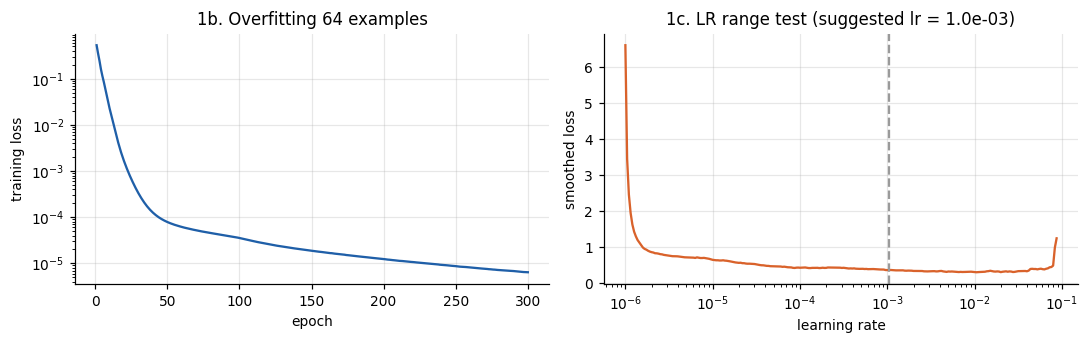

In [6]:
# =====================================================================================================
# STEP 1 — sanity checks before any experiment
# =====================================================================================================
# 1a. Loss at initialization must equal the entropy of the prevalence (bias initialised to the log-odds).
p = yf.mean()
m = new_mlp(fold0.d, dict(hidden=(256, 256, 256)), prior=p).to(DEV)
with torch.no_grad():
    l0 = F.binary_cross_entropy_with_logits(m.eval()(torch.as_tensor(Xf, device=DEV)),
                                            torch.as_tensor(yf, dtype=torch.float32, device=DEV)).item()
print(f'1a  initial loss {l0:.4f} | expected -[p log p + (1-p) log(1-p)] = {-(p * np.log(p) + (1 - p) * np.log(1 - p)):.4f}')

# 1b. A network that cannot memorise 64 examples has a bug.
tiny = train_test_split(np.arange(len(yf)), train_size=64, stratify=yf, random_state=0)[0]
m = fit(new_mlp(fold0.d, {}), Xf[tiny], yf[tiny], c=dict(epochs=300, early_stop=False, lr=1e-3), record=True)
print(f'1b  tiny-batch overfit: final loss {m.hist.loss.iloc[-1]:.5f}, train ROC-AUC {m.hist.train_auc.iloc[-1]:.3f} (expect ~0 and 1.000)')


# 1c. Learning-rate range test (Smith, 2017): increase lr exponentially for one pass, pick ~1/10 of the loss minimum.
def lr_range_test(d_in, X, y, c, lr_min=1e-6, lr_max=1.0, steps=300, seed=0):
    seed_all(seed); model = new_mlp(d_in, c).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr_min)
    Xt, yt = torch.as_tensor(X, device=DEV), torch.as_tensor(y, dtype=torch.float32, device=DEV)
    mult, lrs, losses, avg = (lr_max / lr_min) ** (1 / steps), [], [], None
    for s in range(steps):
        ib = torch.randint(0, len(y), (128,), device=DEV)
        loss = F.binary_cross_entropy_with_logits(model.train()(Xt[ib]), yt[ib])
        opt.zero_grad(); loss.backward(); opt.step()
        avg = loss.item() if avg is None else 0.9 * avg + 0.1 * loss.item()
        lrs.append(opt.param_groups[0]['lr']); losses.append(avg / (1 - 0.9 ** (s + 1)) if s < 50 else avg)
        if s > 20 and avg > 4 * min(losses):
            break
        for g in opt.param_groups:
            g['lr'] *= mult
    return np.array(lrs), np.array(losses)


lrs, losses = lr_range_test(fold0.d, Xf, yf, dict(hidden=(256, 256, 256)))
LR_SUGGEST = float(lrs[np.argmin(losses)] / 10)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(m.hist.epoch, m.hist.loss, color=BLUE); ax[0].set_yscale('log'); ax[0].set_title('1b. Overfitting 64 examples')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('training loss')
ax[1].plot(lrs, losses, color=ORANGE); ax[1].set_xscale('log'); ax[1].axvline(LR_SUGGEST, color=GREY, ls='--')
ax[1].set_title(f'1c. LR range test (suggested lr = {LR_SUGGEST:.1e})'); ax[1].set_xlabel('learning rate'); ax[1].set_ylabel('smoothed loss')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step1_sanity.png'), bbox_inches='tight'); plt.show()

                                         model  train AUC  dev AUC  avoidable bias (proxy - train)  variance (train - dev)
          Bayes-rate proxy (best ML CV, paper)        NaN   0.7400                             NaN                     NaN
                           Logistic regression     0.7591   0.7321                         -0.0191                  0.0270
                                       XGBoost     0.9264   0.7412                         -0.1864                  0.1852
MLP 3x256 (159,233 params), no reg, last epoch     1.0000   0.6547                         -0.2600                  0.3453
    MLP 3x256, no reg, best dev epoch (oracle)     0.9974   0.6945                         -0.2574                  0.3028

Diagnosis: train AUC far above the proxy => no bias problem; the train-dev gap is the problem => VARIANCE.
Ng recipe for high variance: more data (not available: STEP 5 checks how much it would help) or regularization (STEP 3).


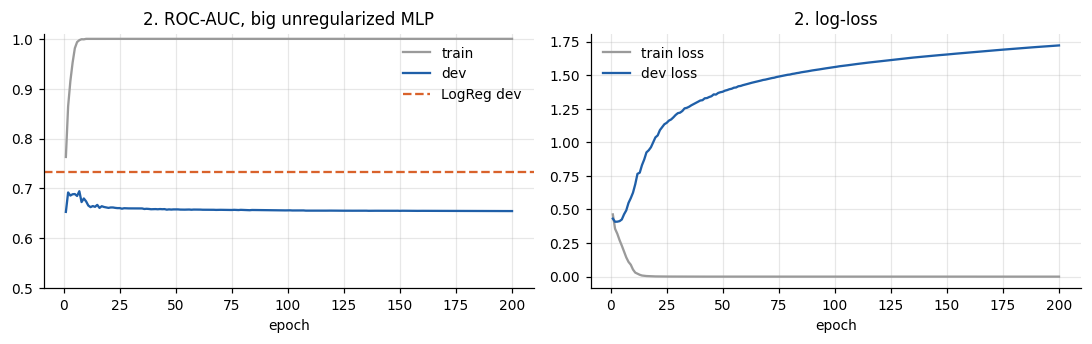

In [7]:
# =====================================================================================================
# STEP 2 — bias / variance diagnosis: big network, no regularization, no early stopping
# =====================================================================================================
lr_ref = LogisticRegression(C=1.0, max_iter=5000).fit(fold0.Xa, fold0.ya)
xgb_ref = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                        eval_metric='logloss', n_jobs=-1, random_state=0).fit(fold0.Xa, fold0.ya)
REF = {'LogReg': (auc(fold0.ya, lr_ref.predict_proba(fold0.Xa)[:, 1]), auc(ydev, lr_ref.predict_proba(Xdev)[:, 1])),
       'XGBoost': (auc(fold0.ya, xgb_ref.predict_proba(fold0.Xa)[:, 1]), auc(ydev, xgb_ref.predict_proba(Xdev)[:, 1]))}

BIG = dict(hidden=(256, 256, 256), lr=1e-3, bs=128, epochs=CFG['ablation_epochs'], early_stop=False)
big = fit(new_mlp(fold0.d, BIG, yf.mean()), Xf, yf, Xe, ye, BIG, monitor=(Xdev, ydev), record=True)
h = big.hist
DIAG = pd.DataFrame([
    {'model': 'Bayes-rate proxy (best ML CV, paper)', 'train AUC': np.nan, 'dev AUC': PAPER['best ML CV (improved)']},
    {'model': 'Logistic regression', 'train AUC': REF['LogReg'][0], 'dev AUC': REF['LogReg'][1]},
    {'model': 'XGBoost', 'train AUC': REF['XGBoost'][0], 'dev AUC': REF['XGBoost'][1]},
    {'model': f'MLP 3x256 ({n_params(big):,} params), no reg, last epoch', 'train AUC': h.train_auc.iloc[-1], 'dev AUC': h.dev_auc.iloc[-1]},
    {'model': 'MLP 3x256, no reg, best dev epoch (oracle)', 'train AUC': h.loc[h.dev_auc.idxmax(), 'train_auc'], 'dev AUC': h.dev_auc.max()}])
DIAG['avoidable bias (proxy - train)'] = PAPER['best ML CV (improved)'] - DIAG['train AUC']
DIAG['variance (train - dev)'] = DIAG['train AUC'] - DIAG['dev AUC']
print(DIAG.round(4).to_string(index=False))
print('\nDiagnosis: train AUC far above the proxy => no bias problem; the train-dev gap is the problem => VARIANCE.'
      '\nNg recipe for high variance: more data (not available: STEP 5 checks how much it would help) or regularization (STEP 3).')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.epoch, h.train_auc, color=GREY, label='train'); ax[0].plot(h.epoch, h.dev_auc, color=BLUE, label='dev')
ax[0].axhline(REF['LogReg'][1], color=ORANGE, ls='--', label='LogReg dev'); ax[0].set_ylim(0.5, 1.01)
ax[0].set_title('2. ROC-AUC, big unregularized MLP'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h.epoch, h.loss, color=GREY, label='train loss'); ax[1].plot(h.epoch, h.dev_loss, color=BLUE, label='dev loss')
ax[1].set_title('2. log-loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step2_bias_variance.png'), bbox_inches='tight'); plt.show()
DIAG.to_csv(os.path.join(OUT, 'step2_bias_variance.csv'), index=False)

In [8]:
# =====================================================================================================
# STEP 3 — regularization ablation (one change at a time from the big network; fixed epochs unless stated)
# =====================================================================================================
ABL = [('none', {})]
ABL += [(f'L2 lambda={l:g}', {'l2': l}) for l in [0.1, 1, 10, 50]]
ABL += [(f'dropout {d}', {'dropout': d}) for d in [0.1, 0.3, 0.5]]
ABL += [('input dropout 0.2', {'input_dropout': 0.2}),
        ('AdamW weight decay 1e-2', {'wd': 1e-2}), ('AdamW weight decay 1e-1', {'wd': 1e-1}),
        ('batch norm', {'bn': True}), ('Gaussian input noise 0.1', {'noise': 0.1}),
        ('label smoothing 0.1', {'label_smoothing': 0.1}), ('mixup alpha 0.2', {'mixup': 0.2}),
        ('max-norm 3', {'max_norm': 3.0}), ('smaller network 1x32', {'hidden': (32,)}),
        ('early stopping (inner split)', {'early_stop': True}),
        ('dropout 0.3 + L2 10', {'dropout': 0.3, 'l2': 10}),
        ('dropout 0.3 + L2 10 + early stopping', {'dropout': 0.3, 'l2': 10, 'early_stop': True}),
        ('dropout 0.5 + batch norm + input dropout 0.2 + ES', {'dropout': 0.5, 'bn': True, 'input_dropout': 0.2, 'early_stop': True})]

rows, curves = [], {}
for name, ov in ABL:
    for s in range(CFG['ablation_seeds']):
        c = {**BIG, **ov}
        t0 = time.time()
        m = fit(new_mlp(fold0.d, c, yf.mean()), Xf, yf, Xe, ye, c, monitor=(Xdev, ydev), record=True, seed=s)
        hh = m.hist
        rows.append(dict(config=name, seed=s, train_auc=auc(yf, predict(m, Xf)), dev_auc=auc(ydev, predict(m, Xdev)),
                         best_dev_auc=hh.dev_auc.max(), best_dev_epoch=int(hh.epoch[hh.dev_auc.idxmax()]),
                         stopped_epoch=int(hh.epoch.iloc[-1]), seconds=time.time() - t0))
        if s == 0:
            curves[name] = hh
    r = pd.DataFrame(rows).query('config == @name')
    print(f'{name:<52} train {r.train_auc.mean():.3f}  dev {r.dev_auc.mean():.3f} +- {r.dev_auc.std() if len(r) > 1 else 0:.3f}  gap {(r.train_auc - r.dev_auc).mean():+.3f}')

abl = pd.DataFrame(rows)
ABL_SUM = abl.groupby('config', sort=False).agg(train_auc=('train_auc', 'mean'), dev_auc=('dev_auc', 'mean'),
                                                 dev_sd=('dev_auc', 'std'), best_dev_auc=('best_dev_auc', 'mean'),
                                                 stopped_epoch=('stopped_epoch', 'mean')).reset_index()
ABL_SUM['gap'] = ABL_SUM.train_auc - ABL_SUM.dev_auc
abl.to_csv(os.path.join(OUT, 'step3_ablation_runs.csv'), index=False)
ABL_SUM.to_csv(os.path.join(OUT, 'step3_ablation_summary.csv'), index=False)
print(f"\nLogReg dev {REF['LogReg'][1]:.3f} | best regularized MLP: {ABL_SUM.loc[ABL_SUM.dev_auc.idxmax(), 'config']} "
      f"({ABL_SUM.dev_auc.max():.3f})")

none                                                 train 1.000  dev 0.652 +- 0.004  gap +0.348
L2 lambda=0.1                                        train 1.000  dev 0.645 +- 0.010  gap +0.355
L2 lambda=1                                          train 1.000  dev 0.641 +- 0.009  gap +0.359
L2 lambda=10                                         train 1.000  dev 0.642 +- 0.003  gap +0.358
L2 lambda=50                                         train 0.999  dev 0.649 +- 0.024  gap +0.350
dropout 0.1                                          train 1.000  dev 0.627 +- 0.021  gap +0.373
dropout 0.3                                          train 1.000  dev 0.638 +- 0.011  gap +0.362
dropout 0.5                                          train 1.000  dev 0.652 +- 0.004  gap +0.348
input dropout 0.2                                    train 1.000  dev 0.629 +- 0.013  gap +0.371
AdamW weight decay 1e-2                              train 1.000  dev 0.648 +- 0.001  gap +0.352


KeyboardInterrupt: 

In [ ]:
# ---------------------------------------------------------------- STEP 3 plots
S = ABL_SUM.sort_values('dev_auc')
fig, ax = plt.subplots(figsize=(8, 0.28 * len(S) + 1))
y_ = np.arange(len(S))
ax.barh(y_, S.dev_auc, xerr=S.dev_sd.fillna(0), color=BLUE, alpha=0.8, label='dev ROC-AUC')
ax.scatter(S.train_auc, y_, color=GREY, marker='|', s=120, label='train ROC-AUC')
ax.axvline(REF['LogReg'][1], color=ORANGE, ls='--', label='LogReg dev')
ax.set_yticks(y_); ax.set_yticklabels(S.config); ax.set_xlim(0.55, 1.0); ax.legend(loc='lower right')
ax.set_title('3. Regularization ablation (diagnostic fold)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step3_ablation_bars.png'), bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for k, (title, keys) in enumerate([('L2', ['none'] + [n for n, _ in ABL if n.startswith('L2')]),
                                   ('dropout', ['none'] + [n for n, _ in ABL if n.startswith('dropout ') and '+' not in n]),
                                   ('others', ['none', 'batch norm', 'mixup alpha 0.2', 'early stopping (inner split)',
                                               'dropout 0.3 + L2 10 + early stopping'])]):
    for i, n in enumerate(keys):
        ax[k].plot(curves[n].epoch, curves[n].dev_auc, lw=1.2, label=n, color=plt.cm.viridis(i / max(1, len(keys) - 1)))
    ax[k].axhline(REF['LogReg'][1], color=ORANGE, ls='--', lw=0.8)
    ax[k].set_title(f'3. dev ROC-AUC per epoch: {title}'); ax[k].set_xlabel('epoch'); ax[k].set_ylim(0.6, 0.76)
    ax[k].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step3_ablation_curves.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 4 — random hyperparameter search (Bergstra & Bengio, 2012), scored by 5-fold CV with early stopping
# =====================================================================================================
FOLDS5 = [make_fold(k, CFG['feature_set']) for k in range(CFG['n_splits'])]


def sample_cfg(rng):
    depth = int(rng.choice([1, 2, 3, 4])); width = int(rng.choice([32, 64, 128, 256, 512]))
    act = str(rng.choice(['relu', 'gelu', 'selu']))
    return dict(hidden=tuple([width] * depth), act=act, bn=bool(rng.random() < 0.3) and act != 'selu',
                dropout=float(rng.uniform(0, 0.5)), input_dropout=float(rng.choice([0, 0.1, 0.2])),
                l2=0.0 if rng.random() < 0.3 else float(10 ** rng.uniform(-1, 2)),
                wd=float(10 ** rng.uniform(-5, -1)), lr=float(10 ** rng.uniform(-4, -2.5)),
                bs=int(rng.choice([64, 128, 256])), label_smoothing=float(rng.choice([0, 0.05, 0.1])),
                mixup=float(rng.choice([0, 0, 0.2, 0.4])), cosine=bool(rng.random() < 0.5), early_stop=True)


def cv_mlp(c, folds, seed=0):
    out = []
    for f in folds:
        xf, yf_, xe, ye_ = f.split()
        m = fit(new_mlp(f.d, c, yf_.mean()), xf, yf_, xe, ye_, c, seed=seed)
        out.append(auc(f.yb, predict(m, f.Xb)))
    return np.array(out)


rng = np.random.default_rng(CFG['seed']); trials = []
for t in range(CFG['n_trials']):
    c = sample_cfg(rng); t0 = time.time(); s = cv_mlp(c, FOLDS5, seed=t)
    trials.append({**c, 'hidden': str(c['hidden']), 'cv_auc': s.mean(), 'cv_sd': s.std(), 'seconds': time.time() - t0})
    print(f"trial {t + 1:>2}/{CFG['n_trials']}  CV {s.mean():.4f} +- {s.std():.4f}  {c['hidden']} {c['act']} drop {c['dropout']:.2f} "
          f"L2 {c['l2']:.2g} wd {c['wd']:.1e} lr {c['lr']:.1e}")
TRIALS = pd.DataFrame(trials).sort_values('cv_auc', ascending=False).reset_index(drop=True)
TRIALS.to_csv(os.path.join(OUT, 'step4_random_search.csv'), index=False)
BEST = TRIALS.iloc[0].to_dict(); BEST['hidden'] = eval(BEST['hidden'])
BEST = {k: BEST[k] for k in sample_cfg(np.random.default_rng(0))}
for k in ['bn', 'cosine', 'early_stop']:
    BEST[k] = bool(BEST[k])
for k in ['bs']:
    BEST[k] = int(BEST[k])
lr_cv = np.array([auc(f.yb, LogisticRegression(C=1.0, max_iter=5000).fit(f.Xa, f.ya).predict_proba(f.Xb)[:, 1]) for f in FOLDS5])
print(f'\nBEST MLP: CV {TRIALS.cv_auc.iloc[0]:.4f} | LogReg on the same 5 folds: {lr_cv.mean():.4f}\n', BEST)
with open(os.path.join(OUT, 'best_mlp_config.json'), 'w') as fh:
    json.dump(BEST, fh, indent=1, default=str)

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, col, lg in zip(ax, ['lr', 'l2', 'dropout', 'wd'], [True, False, False, True]):
    a.scatter(TRIALS[col].replace(0, np.nan) if lg or col == 'l2' else TRIALS[col], TRIALS.cv_auc, s=14, color=BLUE)
    if lg or col == 'l2':
        a.set_xscale('log')
    a.axhline(lr_cv.mean(), color=ORANGE, ls='--', lw=0.8); a.set_xlabel(col); a.set_ylabel('CV ROC-AUC')
ax[0].set_title('4. Random search')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step4_random_search.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 5 — learning curve: would more data fix the variance?
# =====================================================================================================
FR = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]; lc = []
for k, f in enumerate(FOLDS5):
    for fr in FR:
        sub = np.arange(len(f.ya)) if fr == 1.0 else train_test_split(np.arange(len(f.ya)), train_size=fr, stratify=f.ya, random_state=k)[0]
        fi, ei = train_test_split(sub, test_size=CFG['es_frac'], stratify=f.ya[sub], random_state=k)
        m = fit(new_mlp(f.d, BEST, f.ya[fi].mean()), f.Xa[fi], f.ya[fi], f.Xa[ei], f.ya[ei], BEST, seed=k)
        lr_m = LogisticRegression(C=1.0, max_iter=5000).fit(f.Xa[sub], f.ya[sub])
        lc.append(dict(fold=k, frac=fr, n=len(sub), mlp_dev=auc(f.yb, predict(m, f.Xb)), mlp_train=auc(f.ya[fi], predict(m, f.Xa[fi])),
                       lr_dev=auc(f.yb, lr_m.predict_proba(f.Xb)[:, 1]), lr_train=auc(f.ya[sub], lr_m.predict_proba(f.Xa[sub])[:, 1])))
LC = pd.DataFrame(lc).groupby('frac').mean().reset_index()
LC.to_csv(os.path.join(OUT, 'step5_learning_curve.csv'), index=False); print(LC.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(LC.n, LC.mlp_train, 'o--', color=BLUE, alpha=0.5, label='MLP train'); ax.plot(LC.n, LC.mlp_dev, 'o-', color=BLUE, label='MLP dev')
ax.plot(LC.n, LC.lr_train, 's--', color=ORANGE, alpha=0.5, label='LogReg train'); ax.plot(LC.n, LC.lr_dev, 's-', color=ORANGE, label='LogReg dev')
ax.set_xlabel('training adults'); ax.set_ylabel('ROC-AUC'); ax.set_title('5. Learning curve (5-fold)'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step5_learning_curve.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 6 — error analysis on the dev set: where does the network fail?
# =====================================================================================================
best0 = fit(new_mlp(fold0.d, BEST, yf.mean()), Xf, yf, Xe, ye, BEST)
p_mlp, p_lr = predict(best0, Xdev), lr_ref.predict_proba(Xdev)[:, 1]
dev_df = Xtr_df.iloc[CV[0][1]].reset_index(drop=True).assign(y=ydev, p_mlp=p_mlp, p_lr=p_lr)
groups = {'age 18-39': dev_df.RIDAGEYR < 40, 'age 40-59': dev_df.RIDAGEYR.between(40, 59), 'age 60+': dev_df.RIDAGEYR >= 60,
          'U.S.-born': dev_df.DMDBORN4 == 1, 'foreign-born': dev_df.DMDBORN4 == 2,
          'male': dev_df.RIAGENDR == 1, 'female': dev_df.RIAGENDR == 2,
          'Hispanic': dev_df.RIDRETH3.isin([1, 2]), 'NH White': dev_df.RIDRETH3 == 3, 'NH Black': dev_df.RIDRETH3 == 4,
          'NH Asian': dev_df.RIDRETH3 == 6, 'PIR < 1.3': dev_df.INDFMPIR < 1.3, 'PIR >= 1.3': dev_df.INDFMPIR >= 1.3}
ea = []
for g, msk in groups.items():
    d = dev_df[msk.fillna(False)]
    if d.y.nunique() == 2:
        ea.append(dict(group=g, n=len(d), prevalence=d.y.mean(), mean_pred_mlp=d.p_mlp.mean(),
                       auc_mlp=auc(d.y, d.p_mlp), auc_lr=auc(d.y, d.p_lr)))
EA = pd.DataFrame(ea); EA['mlp - lr'] = EA.auc_mlp - EA.auc_lr
print(EA.round(3).to_string(index=False))
thr = np.quantile(p_mlp, 1 - ydev.mean())
fn = dev_df[(dev_df.y == 1) & (dev_df.p_mlp < thr)]; tp = dev_df[(dev_df.y == 1) & (dev_df.p_mlp >= thr)]
print(f'\nMissed positives (FN, n={len(fn)}) vs found positives (TP, n={len(tp)}):')
prof = lambda d: [d.RIDAGEYR.mean(), d.INDFMPIR.mean(), d.DMDEDUC2.mean(), 100 * (d.DMDBORN4 == 2).mean(), 100 * d.RIDRETH3.isin([1, 2]).mean()]
print(pd.DataFrame({'FN (missed)': prof(fn), 'TP (found)': prof(tp)},
                   index=['age', 'poverty-income ratio', 'education (1-5)', 'foreign-born %', 'Hispanic %']).round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].barh(EA.group, EA.auc_mlp, color=BLUE, alpha=0.8, label='MLP'); ax[0].scatter(EA.auc_lr, EA.group, color=ORANGE, zorder=3, label='LogReg')
ax[0].set_xlim(0.4, 0.9); ax[0].set_title('6. dev ROC-AUC by subgroup'); ax[0].legend()
for p_, c_, l_ in [(p_mlp, BLUE, 'MLP'), (p_lr, ORANGE, 'LogReg')]:
    o, pr = calibration_curve(ydev, p_, n_bins=8, strategy='quantile'); ax[1].plot(pr, o, 'o-', color=c_, label=f'{l_} (Brier {brier_score_loss(ydev, p_):.3f})')
ax[1].plot([0, 0.6], [0, 0.6], '--', color=GREY); ax[1].set_title('6. calibration (dev)'); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step6_error_analysis.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 7 — teachers. Soft labels for the training rows are CROSS-FITTED (out-of-fold within the training part),
# otherwise tree teachers hand the student their memorised training predictions (train AUC ~1.0 => useless soft labels).
# =====================================================================================================
def build_sk(name, seed):
    if name == 'lr':
        return LogisticRegression(C=1.0, max_iter=5000)
    if name == 'rf':
        return RandomForestClassifier(n_estimators=500, min_samples_leaf=10, n_jobs=-1, random_state=seed)
    if name == 'xgb':
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', n_jobs=-1, random_state=seed)
    raise KeyError(name)


class DeepEnsemble:
    """Lakshminarayanan et al. (2017): independently initialised copies of the tuned MLP, averaged."""

    def __init__(self, c, members, seed=0):
        self.c, self.members, self.seed, self.models = c, members, seed, []

    def fit(self, X, y):
        self.models = []
        for k in range(self.members):
            fi, ei = train_test_split(np.arange(len(y)), test_size=CFG['es_frac'], stratify=y, random_state=self.seed * 100 + k)
            self.models.append(fit(new_mlp(X.shape[1], self.c, y[fi].mean()), X[fi], y[fi], X[ei], y[ei], self.c,
                                   seed=self.seed * 100 + k))
        return self

    def predict_proba(self, X):
        p = np.mean([predict(m, X) for m in self.models], axis=0)
        return np.column_stack([1 - p, p])


def make_teacher(name, seed):
    return DeepEnsemble(BEST, CFG['teacher_members'], seed) if name == 'dens' else build_sk(name, seed)


def get_teacher(fold, name):
    """Returns {'oof': cross-fitted probs on fold.Xa, 'predict': fn(X) of the teacher refitted on all of fold.Xa, 'inner_auc'}."""
    if name in fold.teachers:
        return fold.teachers[name]
    if name == 'ml_ens':              # the paper's improved-model recipe: LogReg + XGBoost average
        a, b = get_teacher(fold, 'lr'), get_teacher(fold, 'xgb')
        t = dict(oof=(a['oof'] + b['oof']) / 2, predict=lambda X, a=a, b=b: (a['predict'](X) + b['predict'](X)) / 2)
    elif name == 'all':               # every teacher averaged (also the on-policy teacher)
        ts = [get_teacher(fold, n) for n in ['lr', 'rf', 'xgb', 'dens']]
        t = dict(oof=np.mean([x['oof'] for x in ts], 0), predict=lambda X, ts=ts: np.mean([x['predict'](X) for x in ts], 0))
    else:
        oof = np.zeros(len(fold.ya))
        for tr, va in StratifiedKFold(CFG['teacher_inner_folds'], shuffle=True, random_state=fold.seed).split(fold.Xa, fold.ya):
            oof[va] = make_teacher(name, fold.seed).fit(fold.Xa[tr], fold.ya[tr]).predict_proba(fold.Xa[va])[:, 1]
        full = make_teacher(name, fold.seed).fit(fold.Xa, fold.ya)
        if hasattr(full, 'n_jobs'):
            full.set_params(n_jobs=1)     # single-threaded scoring: on-policy distillation queries the teacher every batch
        t = dict(oof=oof, predict=lambda X, full=full: full.predict_proba(X)[:, 1])
    t['inner_auc'] = auc(fold.ya, t['oof'])
    fold.teachers[name] = t
    return t


TEACHERS = ['lr', 'rf', 'xgb', 'dens', 'ml_ens', 'all']
TT = pd.DataFrame([dict(teacher=n, crossfit_train_auc=get_teacher(fold0, n)['inner_auc'],
                        dev_auc=auc(ydev, get_teacher(fold0, n)['predict'](Xdev))) for n in TEACHERS])
print(TT.round(4).to_string(index=False))

In [ ]:
# =====================================================================================================
# STEP 8 — classic knowledge distillation (Hinton et al., 2015): small student learns teacher soft labels
# =====================================================================================================
STUDENT = {**BEST, 'hidden': (64,)}          # compressed student: one hidden layer of 64 units


def train_student(fold, soft=None, c=None, seed=0, arch=None):
    c = {**(arch or STUDENT), **(c or {})}
    xf, yf_, xe, ye_ = fold.split()
    s = None if soft is None else soft[fold.fit_idx]
    return fit(new_mlp(fold.d, c, yf_.mean()), xf, yf_, xe, ye_, c, soft=s, seed=seed)


def dev_score(fn, seeds=None):
    return np.mean([fn(s) for s in range(seeds or CFG['grid_seeds'])])


base_student = dev_score(lambda s: auc(ydev, predict(train_student(fold0, seed=s), Xdev)))
print(f"student alone (1x64, no KD): dev {base_student:.4f} | big tuned MLP: {auc(ydev, predict(best0, Xdev)):.4f} | LogReg {REF['LogReg'][1]:.4f}")
grid = []
for tname in ['dens', 'xgb', 'ml_ens', 'all']:
    soft = get_teacher(fold0, tname)['oof']
    for a in [0.3, 0.5, 0.7, 0.9, 1.0]:
        for T in [1, 2, 4]:
            sc = dev_score(lambda s: auc(ydev, predict(train_student(fold0, soft, dict(alpha=a, T=T), seed=s), Xdev)))
            grid.append(dict(teacher=tname, alpha=a, T=T, dev_auc=sc))
    print(tname, 'best', max(g['dev_auc'] for g in grid if g['teacher'] == tname).round(4))
KDG = pd.DataFrame(grid); KDG.to_csv(os.path.join(OUT, 'step8_kd_grid.csv'), index=False)
kbest = KDG.loc[KDG.dev_auc.idxmax()]
KD_ALPHA, KD_T, KD_TEACHER = float(kbest.alpha), float(kbest['T']), kbest.teacher
print(f'chosen KD: teacher={KD_TEACHER} alpha={KD_ALPHA} T={KD_T} dev={kbest.dev_auc:.4f} (student alone {base_student:.4f})')
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
for a_, tname in zip(ax, ['dens', 'xgb', 'ml_ens', 'all']):
    piv = KDG[KDG.teacher == tname].pivot(index='T', columns='alpha', values='dev_auc')
    im = a_.imshow(piv.values, cmap='viridis', aspect='auto', vmin=KDG.dev_auc.min(), vmax=KDG.dev_auc.max())
    a_.set_xticks(range(piv.shape[1])); a_.set_xticklabels(piv.columns); a_.set_yticks(range(piv.shape[0])); a_.set_yticklabels(piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            a_.text(j, i, f'{piv.values[i, j]:.3f}', ha='center', va='center', fontsize=7, color='white')
    a_.set_title(f'8. KD teacher = {tname}'); a_.set_xlabel('alpha'); a_.set_ylabel('T'); a_.grid(False)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step8_kd_grid.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 9 — multi-teacher KD (MTKD): how to combine LR, RF, XGBoost and the deep ensemble
# =====================================================================================================
def softmax(a, axis=0):
    a = a - a.max(axis=axis, keepdims=True); e = np.exp(a)
    return e / e.sum(axis=axis, keepdims=True)


def mtkd_soft(fold, mode, names=('lr', 'rf', 'xgb', 'dens'), tau=0.01):
    P = np.stack([get_teacher(fold, n)['oof'] for n in names])                       # K x N
    if mode == 'mean':                                                                 # plain average (You et al., 2017)
        return P.mean(0)
    if mode == 'auc':                                                                  # teachers weighted by cross-fitted AUC
        w = softmax(np.array([get_teacher(fold, n)['inner_auc'] for n in names]) / tau)
        return w @ P
    if mode == 'confidence':                                                           # CA-MKD (Zhang et al., ICASSP 2022):
        y = fold.ya[None, :]                                                           # per-sample weight from each teacher's
        ce = -(y * np.log(P.clip(1e-6)) + (1 - y) * np.log((1 - P).clip(1e-6)))       # cross-entropy with the true label
        return (softmax(-ce, axis=0) * P).sum(0)
    if mode == 'logit_mean':                                                           # average in log-odds space
        return 1 / (1 + np.exp(-logit(P).mean(0)))
    raise KeyError(mode)


mt = []
for names in [('lr', 'rf', 'xgb', 'dens'), ('lr', 'xgb', 'dens'), ('rf', 'xgb'), ('lr', 'dens')]:
    for mode in ['mean', 'logit_mean', 'auc', 'confidence']:
        soft = mtkd_soft(fold0, mode, names)
        sc = dev_score(lambda s: auc(ydev, predict(train_student(fold0, soft, dict(alpha=KD_ALPHA, T=KD_T), seed=s), Xdev)))
        mt.append(dict(teachers='+'.join(names), mode=mode, dev_auc=sc))
MT = pd.DataFrame(mt); MT.to_csv(os.path.join(OUT, 'step9_mtkd.csv'), index=False)
print(MT.pivot(index='teachers', columns='mode', values='dev_auc').round(4))
mbest = MT.loc[MT.dev_auc.idxmax()]; MT_MODE, MT_TEACHERS = mbest['mode'], tuple(mbest.teachers.split('+'))
print(f'chosen MTKD: {MT_TEACHERS} / {MT_MODE} dev {mbest.dev_auc:.4f}')

In [ ]:
# =====================================================================================================
# STEP 10 — deep mutual learning (Zhang et al., CVPR 2018): K peers learn from labels AND from each other, no teacher
# =====================================================================================================
def fit_dml(fold, K=2, lam=1.0, c=None, seed=0, T=1.0):
    c = {**STUDENT, **(c or {})}; xf, yf_, xe, ye_ = fold.split()
    seed_all(seed)
    peers = [new_mlp(fold.d, c, yf_.mean()).to(DEV) for _ in range(K)]      # built after seeding => reproducible
    params = [p for m in peers for p in m.parameters()]
    opt = torch.optim.AdamW(params, lr=c['lr'], weight_decay=c['wd'])
    Xt = torch.as_tensor(xf, device=DEV); yt = torch.as_tensor(yf_, dtype=torch.float32, device=DEV)
    best, best_states, bad = -np.inf, None, 0
    for ep in range(c.get('epochs', CFG['max_epochs'])):
        for m in peers:
            m.train()
        perm = torch.randperm(len(yt), device=DEV)
        for k in range(0, len(perm), c['bs']):
            ib = perm[k:k + c['bs']]
            if len(ib) < 2:
                continue
            zs = [m(Xt[ib]) for m in peers]
            loss = 0
            for i in range(K):                       # each peer: CE with labels + mean KL to the (detached) other peers
                mimic = torch.stack([kd_term(zs[i], torch.sigmoid(zs[j]).detach(), T) for j in range(K) if j != i]).mean()
                loss = loss + F.binary_cross_entropy_with_logits(zs[i], yt[ib]) + lam * mimic
                if c.get('l2', 0):
                    loss = loss + c['l2'] / (2 * len(yt)) * l2_penalty(peers[i])
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(params, 5.0); opt.step()
        a = auc(ye_, np.mean([predict(m, xe) for m in peers], 0))
        if a > best + 1e-4:
            best, bad, best_states = a, 0, [copy.deepcopy(m.state_dict()) for m in peers]
        else:
            bad += 1
            if bad >= c.get('patience', CFG['patience']):
                break
    for m, s in zip(peers, best_states):
        m.load_state_dict(s)
    return peers


dml = []
for K in [2, 4]:
    for lam in [0.5, 1.0, 2.0]:
        r = []
        for s in range(CFG['grid_seeds']):
            peers = fit_dml(fold0, K, lam, seed=s); ps = [predict(m, Xdev) for m in peers]
            r.append((np.mean([auc(ydev, p) for p in ps]), auc(ydev, np.mean(ps, 0))))
        dml.append(dict(K=K, lam=lam, single_peer=np.mean([x[0] for x in r]), peer_ensemble=np.mean([x[1] for x in r])))
DML = pd.DataFrame(dml); DML.to_csv(os.path.join(OUT, 'step10_dml.csv'), index=False); print(DML.round(4).to_string(index=False))
dbest = DML.loc[DML.single_peer.idxmax()]; DML_K, DML_LAM = int(dbest.K), float(dbest.lam)
print(f'chosen DML: K={DML_K} lambda={DML_LAM}  (independent student: {base_student:.4f})')

In [ ]:
# =====================================================================================================
# STEP 11 — self-distillation
#   (a) Born-again networks (Furlanello et al., ICML 2018): generation g learns from generation g-1, same architecture
#   (b) BYOT "Be Your Own Teacher" (Zhang et al., ICCV 2019): shallow heads learn from the deepest head inside one network
# =====================================================================================================
def born_again(fold, G=3, c=None, seed=0, alpha=None, T=None):
    c = {**BEST, **(c or {})}; gens = [train_student(fold, None, seed=seed, arch=c)]
    for g in range(1, G + 1):
        soft = predict(gens[-1], fold.Xa)                       # previous generation's predictions on the training rows
        gens.append(train_student(fold, soft, dict(alpha=alpha or KD_ALPHA, T=T or KD_T), seed=seed + g, arch=c))
    return gens


def fit_byot(fold, c=None, seed=0, alpha=0.5, beta=0.05, T=2.0, depth=3, width=128):
    c = {**BEST, **(c or {})}; xf, yf_, xe, ye_ = fold.split()
    model = DeepSupMLP(fold.d, width, depth, c.get('dropout', 0.1), 'relu', yf_.mean())

    def loss_fn(m, xb, yb, ib):
        outs, feats = m(xb, all_heads=True)
        loss = F.binary_cross_entropy_with_logits(outs[-1], yb)
        for o, f in zip(outs[:-1], feats[:-1]):
            loss = loss + (1 - alpha) * F.binary_cross_entropy_with_logits(o, yb) \
                   + alpha * kd_term(o, torch.sigmoid(outs[-1]).detach(), T) \
                   + beta * F.mse_loss(f, feats[-1].detach())
        if c.get('l2', 0):
            loss = loss + c['l2'] / (2 * len(yf_)) * l2_penalty(m)
        return loss
    return fit(model, xf, yf_, xe, ye_, c, loss_fn=loss_fn, seed=seed)


@torch.no_grad()
def predict_heads(model, X):
    model.eval(); outs, _ = model(torch.as_tensor(X, device=DEV), all_heads=True)
    return [torch.sigmoid(o).cpu().numpy() for o in outs]


ba = []
for s in range(CFG['grid_seeds']):
    gens = born_again(fold0, G=3, seed=s * 10); ps = [predict(m, Xdev) for m in gens]
    ba.append([auc(ydev, p) for p in ps] + [auc(ydev, np.mean(ps[1:], 0))])
BA = pd.DataFrame(ba, columns=['gen0 (normal)', 'gen1', 'gen2', 'gen3', 'ensemble gen1-3']).mean()
print('Born-again networks (dev ROC-AUC):\n', BA.round(4).to_string())
by = []
for alpha in [0.3, 0.7]:
    for beta in [0.0, 0.05]:
        r = []
        for s in range(CFG['grid_seeds']):
            hs = predict_heads(fit_byot(fold0, alpha=alpha, beta=beta, seed=s), Xdev)
            r.append([auc(ydev, p) for p in hs] + [auc(ydev, np.mean(hs, 0))])
        by.append(dict(alpha=alpha, beta=beta, **dict(zip(['head1', 'head2', 'head3 (deepest)', 'heads averaged'], np.mean(r, 0)))))
BY = pd.DataFrame(by); print('\nBYOT self-distillation (dev ROC-AUC):\n', BY.round(4).to_string(index=False))
ybest = BY.loc[BY['heads averaged'].idxmax()]; BYOT_A, BYOT_B = float(ybest.alpha), float(ybest.beta)
pd.concat([BA.rename('dev_auc').to_frame().assign(method='born-again'),
           BY.assign(method='byot')]).to_csv(os.path.join(OUT, 'step11_self_distillation.csv'))

In [ ]:
# =====================================================================================================
# STEP 12 — on-policy distillation
# In LLMs (Agarwal et al., ICLR 2024 "GKD"; Thinking Machines 2025) the student samples its OWN outputs and the teacher
# grades them token by token, so the student is trained on the states it actually visits instead of a fixed dataset.
# Tabular analogue used here: at every step the student proposes new inputs around the batch (mixup, Gaussian jitter and
# one adversarial step towards higher student-teacher disagreement), the teacher labels them, and the student trains on
# the proposals where it currently disagrees most with the teacher. Off-policy KD (STEP 8) only ever sees fixed rows.
# Caveat: proposals are made in the preprocessed space, so one-hot columns become fractional; the teachers still score them.
# =====================================================================================================
def fit_onpolicy(fold, teacher='all', c=None, seed=0, alpha=None, T=None, beta=1.0, n_prop=2, keep=0.5, eps=0.15, noise=0.2):
    c = {**STUDENT, **(c or {})}; alpha = KD_ALPHA if alpha is None else alpha; T = KD_T if T is None else T
    tch = get_teacher(fold, teacher); xf, yf_, xe, ye_ = fold.split()
    soft = torch.as_tensor(tch['oof'][fold.fit_idx], dtype=torch.float32, device=DEV)
    base = make_loss(c, soft, len(yf_))

    def loss_fn(m, xb, yb, ib):
        loss = (1 - 0) * base(m, xb, yb, ib)                          # labels + off-policy KD on the real rows
        B = len(xb); rep = xb.repeat(n_prop, 1)
        perm = torch.randperm(len(rep), device=rep.device); lam = torch.rand(len(rep), 1, device=rep.device)
        prop = lam * rep + (1 - lam) * rep[perm] + noise * torch.randn_like(rep)          # student-side proposals
        prop.requires_grad_(True)                                                          # one step uphill on the
        z = m(prop); pt_old = soft[ib].repeat(n_prop)                                     # student's disagreement
        g, = torch.autograd.grad(kd_term(z, pt_old, T), prop)
        prop = (prop + eps * g.sign()).detach()
        with torch.no_grad():
            pt = torch.as_tensor(tch['predict'](prop.cpu().numpy()), dtype=torch.float32, device=DEV)   # teacher grades
            zs = m(prop)
            ps = torch.sigmoid(zs)
            kl = pt * torch.log(pt.clamp(1e-6) / ps.clamp(1e-6)) + (1 - pt) * torch.log((1 - pt).clamp(1e-6) / (1 - ps).clamp(1e-6))
            idx = torch.topk(kl, max(1, int(keep * len(kl)))).indices                     # where the student is most wrong
        return loss + beta * kd_term(m(prop[idx]), pt[idx], T)

    return fit(new_mlp(fold.d, c, yf_.mean()), xf, yf_, xe, ye_, c, loss_fn=loss_fn, seed=seed)


op = []
for tname in ['all', 'ml_ens', 'dens']:
    for beta in [0.5, 1.0]:
        sc = dev_score(lambda s: auc(ydev, predict(fit_onpolicy(fold0, tname, beta=beta, seed=s), Xdev)))
        off = dev_score(lambda s: auc(ydev, predict(train_student(fold0, get_teacher(fold0, tname)['oof'], dict(alpha=KD_ALPHA, T=KD_T), seed=s), Xdev)))
        op.append(dict(teacher=tname, beta=beta, on_policy=sc, off_policy_kd=off))
OP = pd.DataFrame(op); OP['on - off'] = OP.on_policy - OP.off_policy_kd
OP.to_csv(os.path.join(OUT, 'step12_on_policy.csv'), index=False); print(OP.round(4).to_string(index=False))
obest = OP.loc[OP.on_policy.idxmax()]; OP_TEACHER, OP_BETA = obest.teacher, float(obest.beta)

In [ ]:
# =====================================================================================================
# STEP 13 — final comparison: every method on the paper's 5x3 CV folds, for each feature set.
# All choices above were made on the diagnostic fold only; nothing here is re-tuned. Results are appended to a CSV
# after each fold, so an interrupted run resumes where it stopped.
# =====================================================================================================
def m_sk(name):
    return lambda f, s: build_sk(name, s).fit(f.Xa, f.ya).predict_proba(f.Xb)[:, 1]


def m_mlp(c):
    return lambda f, s: predict(train_student(f, None, seed=s, arch=c), f.Xb)


METHODS = {
    'LogReg (paper baseline)': m_sk('lr'),
    'XGBoost (paper config)': m_sk('xgb'),
    'LogReg+XGBoost (paper improved recipe)': lambda f, s: get_teacher(f, 'ml_ens')['predict'](f.Xb),
    'MLP 3x256, no regularization': lambda f, s: predict(fit(new_mlp(f.d, BIG, f.ya.mean()), *f.split(), BIG, seed=s), f.Xb),
    'MLP tuned + regularized (STEP 4)': m_mlp(BEST),
    'MLP student 1x64 alone': m_mlp(STUDENT),
    'Deep ensemble (5x tuned MLP)': lambda f, s: DeepEnsemble(BEST, CFG['ens_members'], s).fit(f.Xa, f.ya).predict_proba(f.Xb)[:, 1],
    'KD (best teacher)': lambda f, s: predict(train_student(f, get_teacher(f, KD_TEACHER)['oof'], dict(alpha=KD_ALPHA, T=KD_T), seed=s), f.Xb),
    'KD (teacher = deep ensemble)': lambda f, s: predict(train_student(f, get_teacher(f, 'dens')['oof'], dict(alpha=KD_ALPHA, T=KD_T), seed=s), f.Xb),
    'MTKD (mean)': lambda f, s: predict(train_student(f, mtkd_soft(f, 'mean', MT_TEACHERS), dict(alpha=KD_ALPHA, T=KD_T), seed=s), f.Xb),
    'MTKD (best weighting)': lambda f, s: predict(train_student(f, mtkd_soft(f, MT_MODE, MT_TEACHERS), dict(alpha=KD_ALPHA, T=KD_T), seed=s), f.Xb),
    'DML (single peer)': lambda f, s: predict(fit_dml(f, DML_K, DML_LAM, seed=s)[0], f.Xb),
    'DML (peer ensemble)': lambda f, s: np.mean([predict(m, f.Xb) for m in fit_dml(f, DML_K, DML_LAM, seed=s)], 0),
    'Born-again (gen 3)': lambda f, s: predict(born_again(f, 3, seed=s)[-1], f.Xb),
    'BYOT self-distillation': lambda f, s: np.mean(predict_heads(fit_byot(f, alpha=BYOT_A, beta=BYOT_B, seed=s), f.Xb), 0),
    'On-policy distillation': lambda f, s: predict(fit_onpolicy(f, OP_TEACHER, beta=OP_BETA, seed=s), f.Xb),
}
CV_CSV = os.path.join(OUT, 'step13_cv_folds.csv')
done = pd.read_csv(CV_CSV) if os.path.exists(CV_CSV) else pd.DataFrame(columns=['feature_set', 'fold', 'method', 'auc', 'seconds'])
for fs in CFG['final_feature_sets']:
    for k in range(len(CV)):
        todo = [m for m in METHODS if not ((done.feature_set == fs) & (done.fold == k) & (done.method == m)).any()]
        if not todo:
            continue
        f = make_fold(k, fs); new = []
        for name in todo:
            t0 = time.time(); p = METHODS[name](f, k)
            new.append(dict(feature_set=fs, fold=k, method=name, auc=auc(f.yb, p), seconds=time.time() - t0))
        done = pd.concat([done, pd.DataFrame(new)], ignore_index=True); done.to_csv(CV_CSV, index=False)
        print(f'{fs} fold {k + 1}/{len(CV)}: ' + ' | '.join(f"{r['method'][:18]} {r['auc']:.3f}" for r in new[:4]) + ' ...')

In [ ]:
# ---------------------------------------------------------------- STEP 13 results: mean +- SD, corrected t-test vs LogReg
cvr = pd.read_csv(CV_CSV); res = []
for fs in CFG['final_feature_sets']:
    d = cvr[cvr.feature_set == fs].pivot(index='fold', columns='method', values='auc')
    ref = d['LogReg (paper baseline)']
    for m in METHODS:
        diff, p = corrected_ttest(d[m], ref) if m != 'LogReg (paper baseline)' else (0.0, np.nan)
        res.append(dict(feature_set=fs, method=m, cv_mean=d[m].mean(), cv_sd=d[m].std(), delta_vs_lr=diff, p_corrected=p,
                        meaningful=bool(diff >= 0.01 and p < 0.05), sec_per_fold=cvr[(cvr.feature_set == fs) & (cvr.method == m)].seconds.mean()))
RES = pd.DataFrame(res); RES.to_csv(os.path.join(OUT, 'step13_cv_summary.csv'), index=False)
for fs in CFG['final_feature_sets']:
    print(f'\n=== feature set: {fs} ===')
    print(RES[RES.feature_set == fs].sort_values('cv_mean', ascending=False).drop(columns='feature_set').round(4).to_string(index=False))

fig, axes = plt.subplots(1, len(CFG['final_feature_sets']), figsize=(7 * len(CFG['final_feature_sets']), 5.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, fs in zip(axes, CFG['final_feature_sets']):
    d = cvr[cvr.feature_set == fs]; order = RES[RES.feature_set == fs].sort_values('cv_mean').method.tolist()
    ax.boxplot([d[d.method == m].auc for m in order], vert=False, widths=0.6, showfliers=False)
    ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order, fontsize=8)
    ax.axvline(d[d.method == 'LogReg (paper baseline)'].auc.mean(), color=ORANGE, ls='--', label='LogReg mean')
    ax.set_title(f'13. {len(CV)}-fold CV ROC-AUC — {fs}'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step13_cv_boxplots.png'), bbox_inches='tight'); plt.show()

In [ ]:
# =====================================================================================================
# STEP 14 — one-shot evaluation on the 1,002 held-out test adults (fit on all 4,004 training adults)
# =====================================================================================================
TEST = {}; trows = []
for fs in CFG['final_feature_sets']:
    f = Fold(Xtr_df, ytr, Xte_df, yte, SETS[fs], seed=CFG['seed'])
    for name in METHODS:
        t0 = time.time(); TEST[(fs, name)] = p = METHODS[name](f, CFG['seed'])
        lo, hi = boot_ci(yte, p)
        trows.append(dict(feature_set=fs, method=name, test_auc=auc(yte, p), ci_lo=lo, ci_hi=hi, brier=brier_score_loss(yte, p),
                          seconds=time.time() - t0))
        print(f'{fs:<9} {name:<42} test {trows[-1]["test_auc"]:.4f} [{lo:.3f}, {hi:.3f}]')
TR = pd.DataFrame(trows); TR[['delta_vs_lr', 'delta_lo', 'delta_hi']] = np.nan
for fs in CFG['final_feature_sets']:
    p0 = TEST[(fs, 'LogReg (paper baseline)')]
    for i in TR.index[TR.feature_set == fs]:
        TR.loc[i, ['delta_vs_lr', 'delta_lo', 'delta_hi']] = paired_boot(yte, TEST[(fs, TR.loc[i, 'method'])], p0)
TR = TR.merge(RES[['feature_set', 'method', 'cv_mean', 'cv_sd', 'p_corrected']], on=['feature_set', 'method'])
TR.to_csv(os.path.join(OUT, 'step14_test_results.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fs = CFG['final_feature_sets'][-1]
for name, col in [('LogReg (paper baseline)', GREY), ('MLP tuned + regularized (STEP 4)', BLUE), ('Deep ensemble (5x tuned MLP)', GREEN),
                  ('KD (best teacher)', ORANGE), ('MTKD (best weighting)', PURPLE), ('On-policy distillation', RED)]:
    fpr, tpr, _ = roc_curve(yte, TEST[(fs, name)]); axes[0].plot(fpr, tpr, color=col, lw=1.2, label=f'{name} ({auc(yte, TEST[(fs, name)]):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color=GREY, lw=0.8); axes[0].set_title(f'14. Test ROC — {fs}'); axes[0].legend(fontsize=7, loc='lower right')
d = TR[TR.feature_set == fs].sort_values('delta_vs_lr')
axes[1].errorbar(d.delta_vs_lr, range(len(d)), xerr=[d.delta_vs_lr - d.delta_lo, d.delta_hi - d.delta_vs_lr], fmt='o', color=BLUE, ms=4)
axes[1].axvline(0, color=GREY, ls='--'); axes[1].set_yticks(range(len(d))); axes[1].set_yticklabels(d.method, fontsize=8)
axes[1].set_xlabel('test ROC-AUC gain over LogReg (paired bootstrap 95% CI)'); axes[1].set_title(f'14. Gain vs LogReg — {fs}')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'step14_test.png'), bbox_inches='tight'); plt.show()

In [ ]:
# ---------------------------------------------------------------- final summary
line = '=' * 112
print(line); print('  DEEP LEARNING vs THE ML PAPER — NHANES 2013-2014 Toxoplasma IgG'); print(line)
print(f"  paper: LogReg baseline CV {PAPER['LR baseline CV']:.3f} / test {PAPER['LR baseline test']:.3f};  "
      f"improved ML CV {PAPER['best ML CV (improved)']:.3f} / test {PAPER['best ML test (improved)']:.3f}")
print(f'  STEP 2  big MLP: train {DIAG.iloc[3]["train AUC"]:.3f} vs dev {DIAG.iloc[3]["dev AUC"]:.3f}  => variance problem')
print(f'  STEP 3  best single regularizer: {ABL_SUM.loc[ABL_SUM.dev_auc.idxmax(), "config"]} (dev {ABL_SUM.dev_auc.max():.3f})')
print(f'  STEP 4  tuned MLP: {BEST["hidden"]} {BEST["act"]} dropout {BEST["dropout"]:.2f} L2 {BEST["l2"]:.3g} wd {BEST["wd"]:.1e} lr {BEST["lr"]:.1e}')
print(f'  KD: teacher {KD_TEACHER}, alpha {KD_ALPHA}, T {KD_T} | MTKD: {"+".join(MT_TEACHERS)} / {MT_MODE} | DML K={DML_K} lambda={DML_LAM} | '
      f'BYOT alpha={BYOT_A} beta={BYOT_B} | on-policy teacher {OP_TEACHER} beta {OP_BETA}')
print(line)
show = TR[['feature_set', 'method', 'cv_mean', 'cv_sd', 'p_corrected', 'test_auc', 'ci_lo', 'ci_hi', 'delta_vs_lr']]
print(show.sort_values(['feature_set', 'cv_mean'], ascending=[True, False]).round(4).to_string(index=False))
print(line)
best_row = RES.sort_values('cv_mean', ascending=False).iloc[0]
print(f"  best by CV: {best_row.method} on {best_row.feature_set}: CV {best_row.cv_mean:.4f} "
      f"(delta vs LogReg {best_row.delta_vs_lr:+.4f}, corrected p = {best_row.p_corrected:.3g}, meaningful = {best_row.meaningful})")
print(line)
with open(os.path.join(OUT, 'chosen_settings.json'), 'w') as fh:
    json.dump({'BEST': {k: str(v) for k, v in BEST.items()}, 'KD': [KD_TEACHER, KD_ALPHA, KD_T], 'MTKD': [MT_TEACHERS, MT_MODE],
               'DML': [DML_K, DML_LAM], 'BYOT': [BYOT_A, BYOT_B], 'ON_POLICY': [OP_TEACHER, OP_BETA]}, fh, indent=1, default=str)